In [15]:
library(readr)

# Wczytywanie danych
wine <- read_csv("wineR3_4.csv")

# Konwersja kolumny Class na factor
wine$Class <- as.factor(wine$Class)

# Ładowanie bibliotek
library(e1071)
library(GGally)
library(ggplot2)

# Sprawdzenie struktury i podgląd danych
str(wine)
head(wine, 5)



Rows: 178 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): Class
dbl (4): Flavanoids, Hue, OD, Proline

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


spc_tbl_ [178 × 5] (S3: spec_tbl_df/tbl_df/tbl/data.frame)
 $ Flavanoids: num [1:178] 3.06 2.76 3.24 3.49 2.69 3.39 2.52 2.51 2.98 3.15 ...
 $ Hue       : num [1:178] 1.04 1.05 1.03 0.86 1.04 1.05 1.02 1.06 1.08 1.01 ...
 $ OD        : num [1:178] 3.92 3.4 3.17 3.45 2.93 2.85 3.58 3.58 2.85 3.55 ...
 $ Proline   : num [1:178] 1065 1050 1185 1480 735 ...
 $ Class     : Factor w/ 3 levels "Low","Middle",..: 3 3 3 3 3 3 3 3 3 3 ...
 - attr(*, "spec")=
  .. cols(
  ..   Flavanoids = col_double(),
  ..   Hue = col_double(),
  ..   OD = col_double(),
  ..   Proline = col_double(),
  ..   Class = col_character()
  .. )
 - attr(*, "problems")=<externalptr> 


Flavanoids,Hue,OD,Proline,Class
<dbl>,<dbl>,<dbl>,<dbl>,<fct>
3.06,1.04,3.92,1065,Premium
2.76,1.05,3.40,1050,Premium
3.24,1.03,3.17,1185,Premium
3.49,0.86,3.45,1480,Premium
2.69,1.04,2.93,735,Premium


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


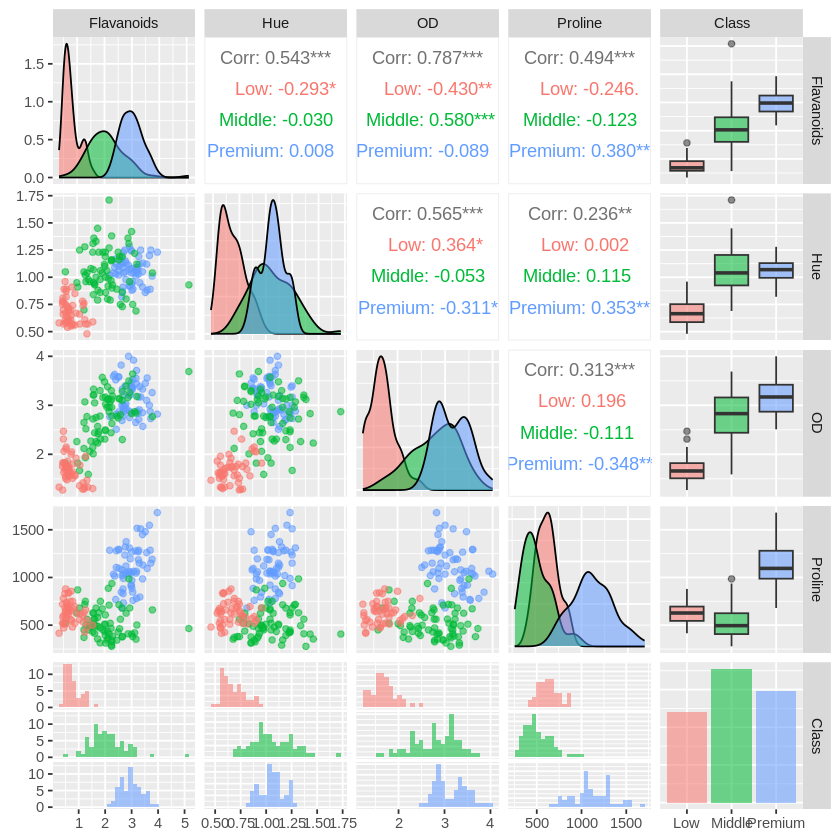

In [16]:
# Create SVM Model
# RADIAL

svm_model <- svm(Class ~ ., data=wine, type = "C-classification",
                 kernel="radial") #linear/polynomial/sigmoid

ggpairs(wine, ggplot2::aes(colour = Class, alpha = 0.4))

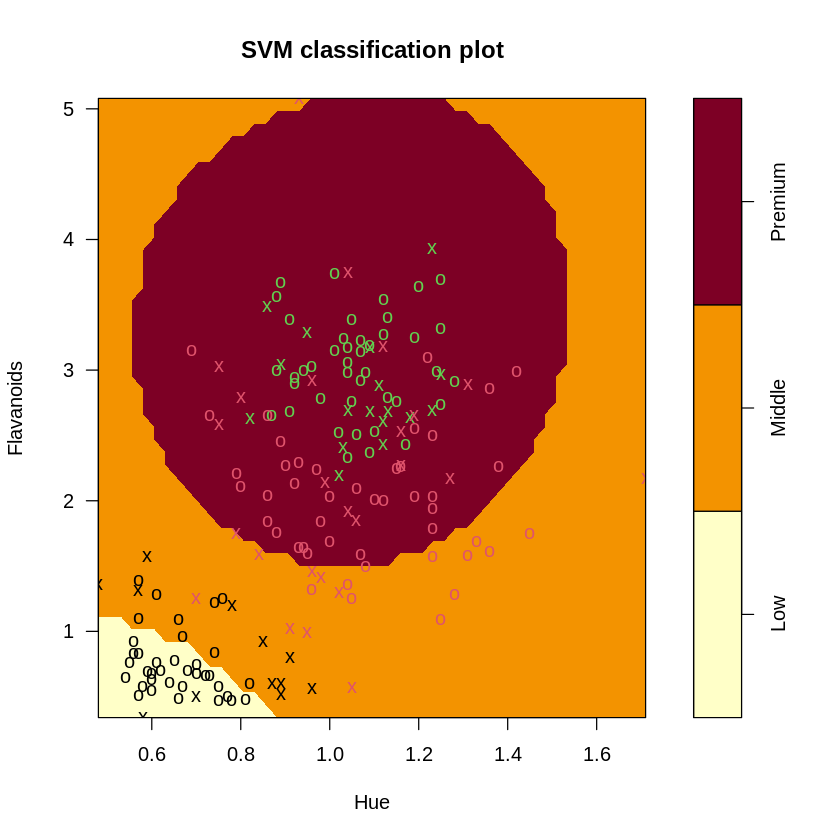

In [17]:
# Wizualizacja modelu SVM
plot(svm_model, data=wine,
     Flavanoids ~ Hue,
     slice = list(OD=3, Proline=1000)
)

         Actual
Predicted Low Middle Premium
  Low      48      2       0
  Middle    0     65       2
  Premium   0      4      57

[1] 0.04494382

[1] 0.9550562

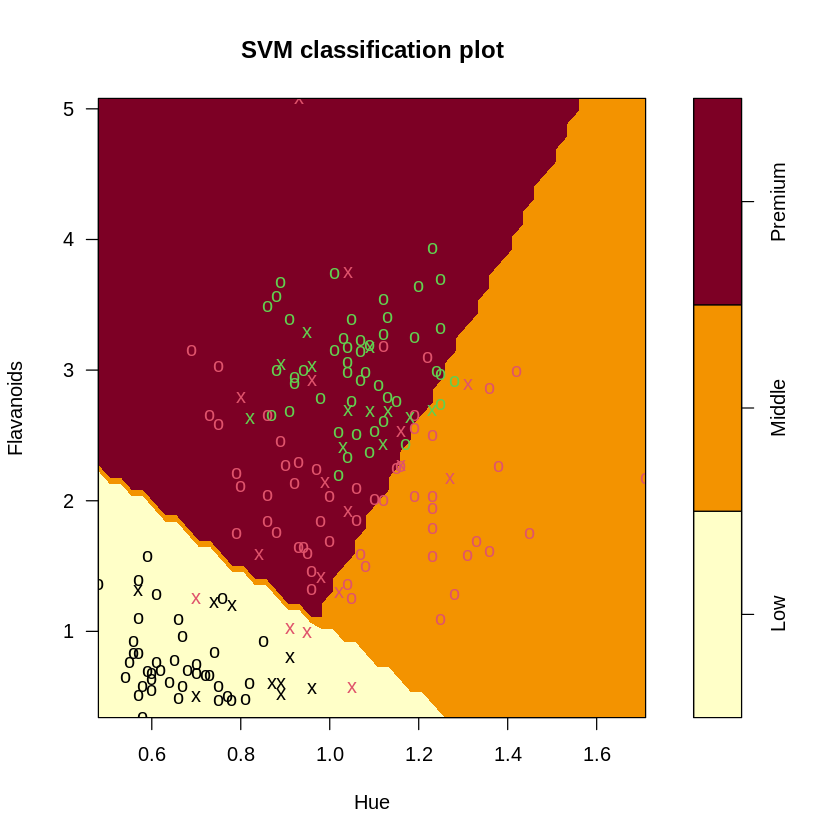

In [18]:

pred = predict(svm_model, wine)
tab = table(Predicted=pred, Actual = wine$Class)
tab

# Obliczanie błędów i dokładności
1-sum(diag(tab))/sum(tab) #Missclasification error

sum(diag(tab))/sum(tab) #Accuracy

#LINEAR

svm_model <- svm(Class ~ ., data=wine, type = "C-classification",
                 kernel="linear") #linear/polynomial/sigmoid

# Wizualizacja modelu liniowego
plot(svm_model, data=wine,
     Flavanoids~Hue,
     slice = list(OD=2, Proline=1000)
)

         Actual
Predicted Low Middle Premium
  Low      48      3       0
  Middle    0     65       2
  Premium   0      3      57

[1] 0.04494382

[1] 0.9550562

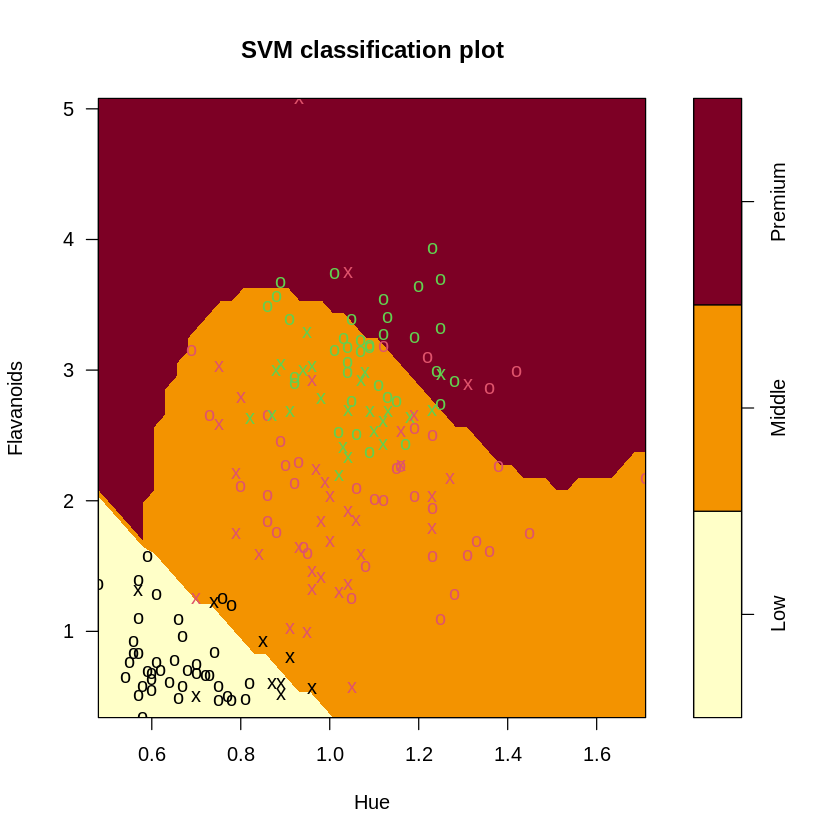

In [19]:

pred = predict(svm_model, wine)
tab = table(Predicted=pred, Actual = wine$Class)
tab

# Miary błędu i dokładności
1-sum(diag(tab))/sum(tab)
sum(diag(tab))/sum(tab)

#POLYNOMIAL

svm_model <- svm(Class ~ ., data=wine, type = "C-classification",
                 kernel="poly") #linear/polynomial/sigmoid

# Wizualizacja modelu wielomianowego
plot(svm_model, data=wine,
     Flavanoids~Hue,
     slice = list(OD=2, Proline=1000)
)

         Actual
Predicted Low Middle Premium
  Low      47      0       0
  Middle    1     70       5
  Premium   0      1      54

[1] 0.03932584

[1] 0.9606742

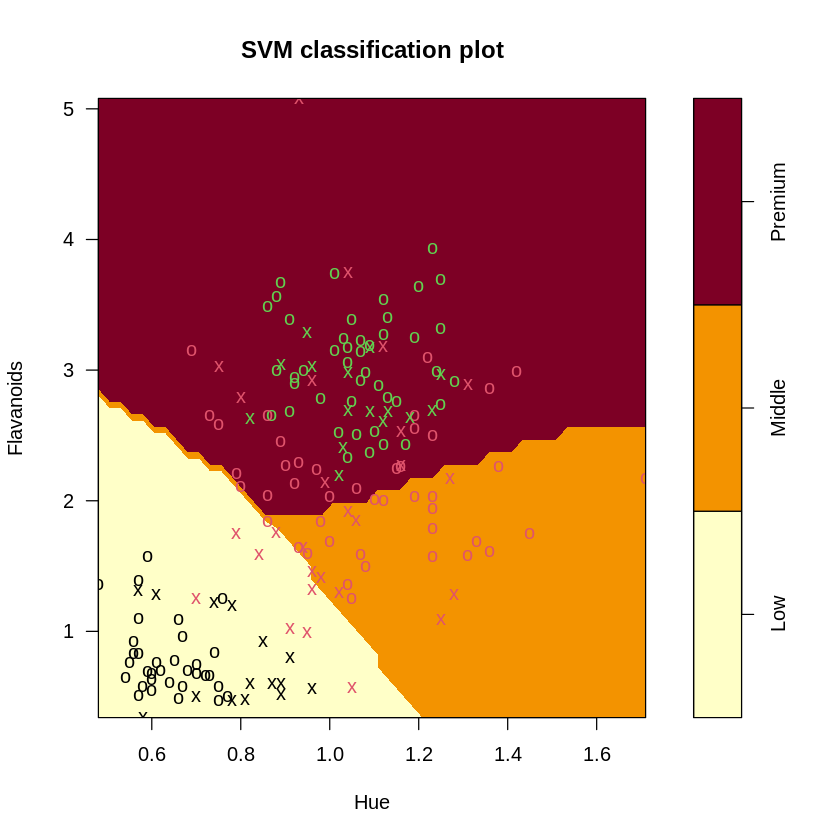

In [20]:
#Predict each Species
#Confusion matrix and missclassification Error and Accuracy

pred = predict(svm_model, wine)
tab = table(Predicted=pred, Actual = wine$Class)
tab

# Miary błędu i dokładności
1-sum(diag(tab))/sum(tab)
sum(diag(tab))/sum(tab)

#SIGMOID

svm_model <- svm(Class ~ ., data=wine, type = "C-classification",
                 kernel="sigmoid") #linear/polynomial/sigmoid

# Wizualizacja modelu sigmoidalnego
plot(svm_model, data=wine,
     Flavanoids~Hue,
     slice = list(OD=2, Proline=1000)
)

         Actual
Predicted Low Middle Premium
  Low      48      6       0
  Middle    0     60       2
  Premium   0      5      57

[1] 0.07303371

[1] 0.9269663

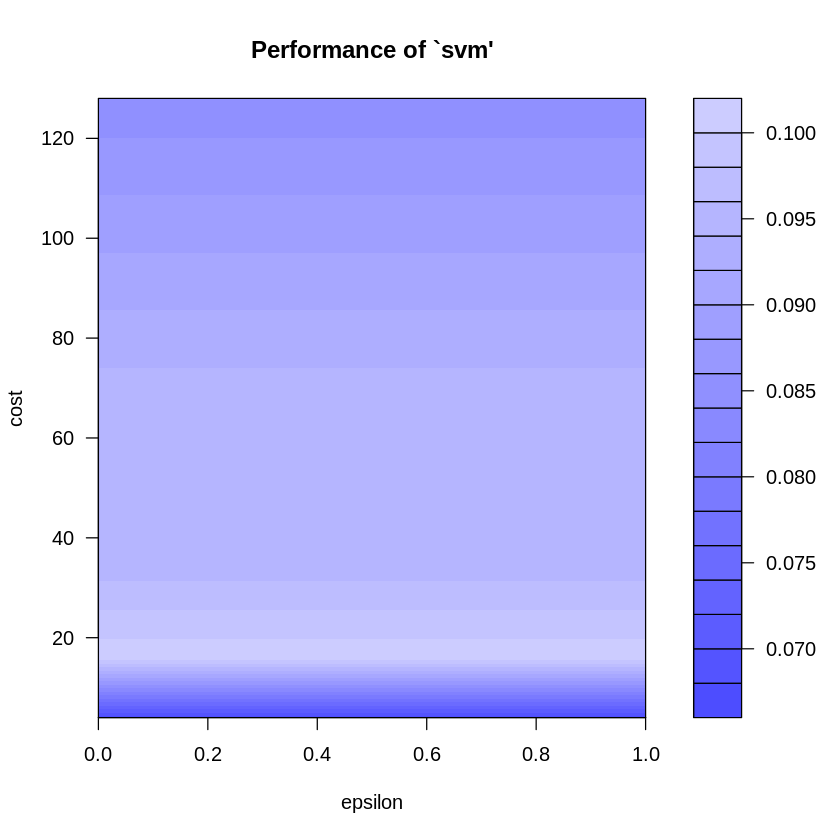

In [21]:
#Predict each Species
#Confusion matrix and missclassification Error and Accuracy

pred = predict(svm_model, wine)
tab = table(Predicted=pred, Actual = wine$Class)
tab

# Miary błędu i dokładności
1-sum(diag(tab))/sum(tab)
sum(diag(tab))/sum(tab)

#Parameter Tunning

set.seed(123)
tmodel=tune(type = "C-classification", svm, Class~., data=wine,
            ranges=list(epsilon= seq(0, 1, 0.1), cost = 2^(2:7)))
plot(tmodel)

In [23]:
summary(tmodel)


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 epsilon cost
       0    4

- best performance: 0.06732026 

- Detailed performance results:
   epsilon cost      error dispersion
1      0.0    4 0.06732026 0.04460116
2      0.1    4 0.06732026 0.04460116
3      0.2    4 0.06732026 0.04460116
4      0.3    4 0.06732026 0.04460116
5      0.4    4 0.06732026 0.04460116
6      0.5    4 0.06732026 0.04460116
7      0.6    4 0.06732026 0.04460116
8      0.7    4 0.06732026 0.04460116
9      0.8    4 0.06732026 0.04460116
10     0.9    4 0.06732026 0.04460116
11     1.0    4 0.06732026 0.04460116
12     0.0    8 0.07875817 0.04724329
13     0.1    8 0.07875817 0.04724329
14     0.2    8 0.07875817 0.04724329
15     0.3    8 0.07875817 0.04724329
16     0.4    8 0.07875817 0.04724329
17     0.5    8 0.07875817 0.04724329
18     0.6    8 0.07875817 0.04724329
19     0.7    8 0.07875817 0.04724329
20     0.8    8 0.07875817 0.04724329
21     0.9    

In [24]:
# Wybór i podsumowanie najlepszego modelu
mymodel = tmodel$best.model
summary(mymodel)


Call:
best.tune(METHOD = svm, train.x = Class ~ ., data = wine, ranges = list(epsilon = seq(0, 
    1, 0.1), cost = 2^(2:7)), type = "C-classification")


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  4 

Number of Support Vectors:  45

 ( 14 19 12 )


Number of Classes:  3 

Levels: 
 Low Middle Premium




In [25]:
# Best model
mymodel = tmodel$best.model
summary(mymodel)


Call:
best.tune(METHOD = svm, train.x = Class ~ ., data = wine, ranges = list(epsilon = seq(0, 
    1, 0.1), cost = 2^(2:7)), type = "C-classification")


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  4 

Number of Support Vectors:  45

 ( 14 19 12 )


Number of Classes:  3 

Levels: 
 Low Middle Premium




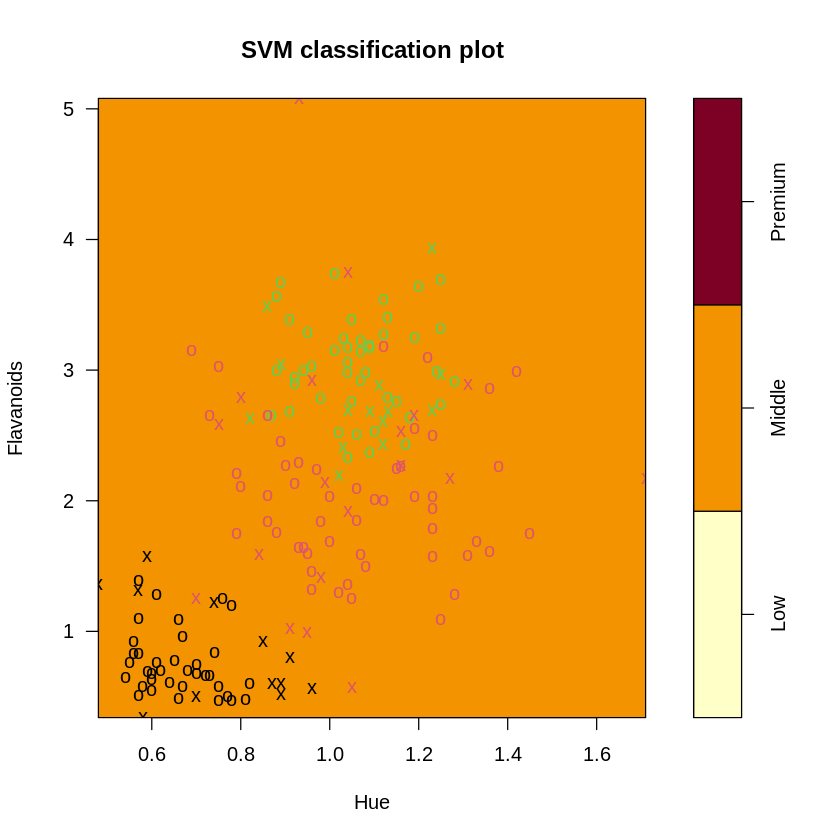

In [26]:
# RADIAL model was selected as the best
plot(mymodel, data=wine,
     Flavanoids ~ Hue,
     slice = list(OD=2, Proline=4)
)

In [27]:
# Confusion matrix and missclassification rate and accuracy using best parameter

pred1 = predict(mymodel, wine)
tab1 = table(Predicted=pred1, Actual = wine$Class)
tab1

# Obliczanie błędu (Missclassification rate)
1-sum(diag(tab1))/sum(tab1)

# Obliczanie dokładności (Accuracy)
sum(diag(tab1))/sum(tab1)

         Actual
Predicted Low Middle Premium
  Low      48      1       0
  Middle    0     66       1
  Premium   0      4      58

[1] 0.03370787

[1] 0.9662921